# Module 1 Lab — Classical Anomaly Detection on Tabular Data
**MSCA Doctoral Programme · Anomaly Detection · Day 1**

In this lab you will train and **benchmark** three classical, *unsupervised* anomaly
detectors on imbalanced tabular data, then watch the same pipeline **transfer** to a
second use case.

**You will be able to:**
1. run an EDA that exposes class imbalance and class overlap;
2. train **Isolation Forest**, **LOF**, and **One-Class SVM** without using labels to fit;
3. read **anomaly-score distributions** and **tune a threshold** to balance precision & recall;
4. compare models with **PR-AUC** (not accuracy) and justify a choice.

**How to run:** works in Google Colab or local Jupyter. The data cells try the real
Kaggle dataset first and fall back to a synthetic look-alike if the download is
unavailable, so the notebook always runs offline.

**Datasets:** [Credit Card Fraud (Kaggle)](https://www.kaggle.com/datasets/mlg-ulb/creditcardfraud) ·
[KDD Cup 1999 (Kaggle)](https://www.kaggle.com/datasets/galaxyh/kdd-cup-1999-data). Each part starts
with an *About the data* card explaining the columns.


## 0 · Environment setup

In [ ]:
# Portable setup: install anything missing (Colab or local), then import.
import importlib, subprocess, sys
def _ensure(pkgs):
    for mod, pip in pkgs:
        try:
            importlib.import_module(mod)
        except ImportError:
            print(f"installing {pip} ...")
            subprocess.run([sys.executable, "-m", "pip", "install", "-q", pip], check=False)
_ensure([("sklearn","scikit-learn"), ("seaborn","seaborn"),
         ("pandas","pandas"), ("numpy","numpy"), ("matplotlib","matplotlib")])

import os, time, warnings
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
from pathlib import Path
warnings.filterwarnings("ignore")

RNG = 42
np.random.seed(RNG)
sns.set_theme(style="whitegrid", context="talk")
plt.rcParams["figure.figsize"] = (9, 5)
print("Environment ready.")

## 1 · Data loaders (real, with offline-safe synthetic fallback)

Each loader tries the real dataset first; if the download is unavailable it builds a
synthetic look-alike with the same shape (heavy imbalance, overlapping classes). Set the
environment variable `LAB_FORCE_SYNTHETIC=1` to force the fallback.

In [ ]:
FORCE_SYNTH = os.environ.get("LAB_FORCE_SYNTHETIC", "0") == "1"

def _synthetic_fraud(n=40000, frac_pos=0.004, seed=RNG):
    # Normal = a dense correlated cluster; anomalies = genuine low-density outliers
    # (shifted on a random subset of dims), so UNSUPERVISED detectors actually separate
    # them — mirroring how IF/LOF behave on the real dataset.
    rng = np.random.default_rng(seed)
    d = 28
    n_pos = max(60, int(n * frac_pos)); n_neg = n - n_pos
    A = rng.normal(0, 1, size=(d, d)); cov = (A @ A.T) / d + np.eye(d) * 0.5
    Xn = rng.multivariate_normal(np.zeros(d), cov, size=n_neg)
    Xa = rng.multivariate_normal(np.zeros(d), cov, size=n_pos) * 1.3
    dims = rng.choice(d, 8, replace=False)
    shift = rng.choice([-1.0, 1.0], size=8) * rng.uniform(2.5, 4.0, size=8)
    scale = rng.uniform(0.35, 1.0, size=(n_pos, 1))      # a third of anomalies are subtle
    Xa[:, dims] += shift * scale
    X = np.vstack([Xn, Xa]); y = np.r_[np.zeros(n_neg, int), np.ones(n_pos, int)]
    df = pd.DataFrame(X, columns=[f"V{i}" for i in range(1, 29)])
    amt = np.expm1(rng.normal(3.0, 1.2, size=len(df))).clip(0, 25000)
    amt[y == 1] *= rng.uniform(1.2, 3.0, size=int((y == 1).sum()))
    df["Amount"] = np.round(amt, 2)
    df["Time"] = np.sort(rng.uniform(0, 172792, size=len(df)))
    df["Class"] = y
    return df.sample(frac=1, random_state=seed).reset_index(drop=True)

def load_fraud():
    """Credit Card Fraud (Kaggle mlg-ulb/creditcardfraud) with synthetic fallback."""
    if not FORCE_SYNTH:
        try:
            import kagglehub
            path = kagglehub.dataset_download("mlg-ulb/creditcardfraud")
            df = pd.read_csv(next(Path(path).glob("*.csv")))
            print(f"Loaded REAL Credit Card Fraud: {df.shape}")
            return df
        except Exception as e:
            print(f"[fallback] real fraud unavailable ({type(e).__name__}); using synthetic.")
    df = _synthetic_fraud()
    print(f"Loaded SYNTHETIC fraud-like data: {df.shape}")
    return df

def _synthetic_intrusion(n=30000, frac_pos=0.09, seed=RNG + 1):
    rng = np.random.default_rng(seed)
    d = 12
    n_pos = max(100, int(n * frac_pos)); n_neg = n - n_pos
    Xn = rng.normal(0, 1, size=(n_neg, d))
    Xa = rng.normal(0, 1, size=(n_pos, d)) * 1.4
    dims = rng.choice(d, 5, replace=False)
    shift = rng.choice([-1.0, 1.0], size=5) * rng.uniform(2.0, 3.5, size=5)
    scale = rng.uniform(0.4, 1.0, size=(n_pos, 1))
    Xa[:, dims] += shift * scale
    X = np.vstack([Xn, Xa]); y = np.r_[np.zeros(n_neg, int), np.ones(n_pos, int)]
    cols = ["duration","src_bytes","dst_bytes","count","srv_count","dst_host_count",
            "serror_rate","rerror_rate","same_srv_rate","diff_srv_rate","logged_in","hot"]
    df = pd.DataFrame(X, columns=cols)
    df["attack"] = y
    return df.sample(frac=1, random_state=seed).reset_index(drop=True)

def load_intrusion():
    """KDD Cup 99 (SA subset) with synthetic fallback. Use case 2: network intrusion."""
    if not FORCE_SYNTH:
        try:
            from sklearn.datasets import fetch_kddcup99
            d = fetch_kddcup99(subset="SA", percent10=True, as_frame=True, random_state=RNG)
            df = d.frame.copy()
            lab = df["labels"].astype(str).str.replace("b'", "", regex=False).str.strip("'.")
            y = (lab != "normal").astype(int)
            df = df.drop(columns=["labels"])
            # fetch_kddcup99 returns every column as object: convert numerics, one-hot only the 3 categoricals
            cats = ["protocol_type", "service", "flag"]
            num = df.columns.difference(cats)
            df[num] = df[num].apply(pd.to_numeric)
            df = pd.get_dummies(df, columns=cats, drop_first=True, dtype=float)
            df["attack"] = y.values
            print(f"Loaded REAL KDD intrusion: {df.shape}")
            return df
        except Exception as e:
            print(f"[fallback] real KDD unavailable ({type(e).__name__}); using synthetic.")
    df = _synthetic_intrusion()
    print(f"Loaded SYNTHETIC intrusion-like data: {df.shape}")
    return df

def subsample(df, label, n_normal=20000, seed=RNG):
    """Keep every anomaly + a sample of normals, so the lab runs fast."""
    pos = df[df[label] == 1]
    neg = df[df[label] == 0].sample(min(n_normal, int((df[label] == 0).sum())), random_state=seed)
    return pd.concat([pos, neg]).sample(frac=1, random_state=seed).reset_index(drop=True)
print("loaders ready.")

---
## PART A · Credit Card Fraud

A **point-anomaly** problem: each fraudulent transaction is odd on its own.

### About the data · Credit Card Fraud

**Source:** [Kaggle · mlg-ulb/creditcardfraud](https://www.kaggle.com/datasets/mlg-ulb/creditcardfraud),
released by the Machine Learning Group of the Université Libre de Bruxelles (ULB) together with
Worldline (Dal Pozzolo et al., 2015). Licence: Open Database License (ODbL).

**What one row is:** one card payment made by a European cardholder over **two days in
September 2013**. 284,807 payments, of which **492 are fraud (0.17 %)**.

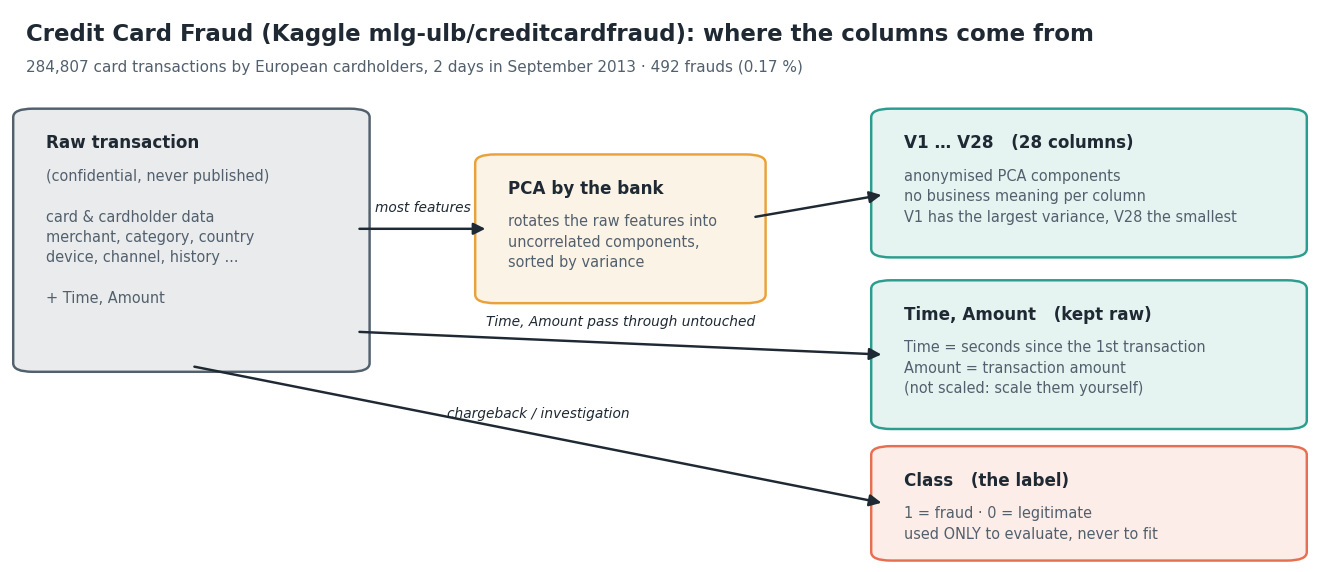

| Column | Type | Meaning |
|---|---|---|
| `Time` | float, seconds | Seconds since the **first** transaction in the file (0 → 172,792 s ≈ 48 h). Not a clock time. |
| `V1` … `V28` | float | **PCA components** of the original, confidential features. Each one mixes many raw attributes, so no `V` has a business meaning on its own. Already centred at 0; `V1` has the largest variance, `V28` the smallest. |
| `Amount` | float | Transaction amount, **not** transformed: heavily skewed (most payments are small, a few reach ~25,000). The currency is not stated. |
| `Class` | 0 / 1 | **Label**: 1 = fraud (confirmed after the fact, e.g. chargeback), 0 = legitimate. We fit detectors **without** it and use it only to evaluate. |

**Why it is anonymised:** the bank could not publish card numbers, merchants or locations. PCA
keeps the *structure* that separates fraud while hiding what each feature was. The cost: you
cannot explain a flag in business terms ("unusual country"), only as "far out on V14".

**What you should see when you run the next two cells**

- `Loaded REAL Credit Card Fraud: (284807, 31)`, then `0: 284315` and `1: 492`, fraud rate `0.1727%`.
- After `subsample(...)`: `(20492, 31) | contamination = 0.0240`. We keep **all** 492 frauds and
  20,000 random normals, so the lab runs in seconds. This raises the fraud rate from 0.17 % to
  2.4 %: easier than production, and something to remember when reading the metrics.
- If the first line says `SYNTHETIC` instead of `REAL`, the Kaggle download failed and the
  notebook uses a simulated look-alike: your plots and scores will differ from your neighbours'.


In [ ]:
fraud = load_fraud()
print(fraud["Class"].value_counts())
print("fraud rate: %.4f%%" % (100 * fraud["Class"].mean()))
fraud.head()

In [ ]:
fraud_s = subsample(fraud, "Class", n_normal=20000)
print(fraud_s.shape, "| contamination = %.4f" % fraud_s["Class"].mean())

### A1 · EDA — imbalance and overlap
Two questions decide everything downstream: **how rare** are anomalies, and **how much do
the classes overlap** in feature space?

In [ ]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
fraud_s["Class"].value_counts().sort_index().plot(kind="bar", ax=ax[0], color=["#2a9d8f", "#e76f51"], rot=0)
ax[0].set_yscale("log"); ax[0].set_ylim(bottom=1)  # log scale: fraud is ~2% of normal, invisible on a linear axis
ax[0].bar_label(ax[0].containers[0])
ax[0].set_title("Class balance (0=normal, 1=fraud) — log scale"); ax[0].set_ylabel("count (log)")
sns.kdeplot(data=fraud_s, x="Amount", hue="Class", common_norm=False, clip=(0, 2000), ax=ax[1])
ax[1].set_title("Amount distribution by class")
plt.tight_layout(); plt.show()

In [ ]:
# 2D PCA — a quick visual of how badly the classes overlap
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
feat = [c for c in fraud_s.columns if c != "Class"]
Xp = StandardScaler().fit_transform(fraud_s[feat])
pc = PCA(n_components=2, random_state=RNG).fit_transform(Xp)
idx = np.random.RandomState(RNG).permutation(len(pc))[:6000]
plt.figure(figsize=(7, 6))
plt.scatter(pc[idx, 0], pc[idx, 1], c=fraud_s["Class"].values[idx],
            cmap="coolwarm", s=8, alpha=0.5)
plt.title("2D PCA — do the classes overlap?"); plt.xlabel("PC1"); plt.ylabel("PC2")
plt.show()

### A2 · Preprocess & split  ✏️
Scale the features and make a **stratified** train/test split. Fit the scaler on the
**training set only** — fitting on all data leaks test information.

In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import RobustScaler
feat = [c for c in fraud_s.columns if c != "Class"]
X = fraud_s[feat].values; y = fraud_s["Class"].values

# TODO: make a stratified 60/40 train/test split (random_state=RNG)
# X_train, X_test, y_train, y_test = ...

# TODO: fit a RobustScaler on X_train ONLY, then transform both X_train and X_test
# scaler = ...
# X_train = ...; X_test = ...

contam = y_train.mean()   # share of anomalies in training data
print("contamination = %.4f" % contam)

### A3 · Scoring helpers
We standardise every model to **"higher score = more anomalous"**, then evaluate with
**ROC-AUC** and **PR-AUC**. The threshold flags the top-`contamination` fraction.

In [ ]:
from sklearn.metrics import (roc_auc_score, average_precision_score,
    precision_recall_curve, precision_score, recall_score, f1_score)

def anomaly_scores(model, X):
    """Higher = more anomalous, regardless of estimator convention."""
    if hasattr(model, "score_samples"):
        return -model.score_samples(X)
    return -model.decision_function(X)

def tune_threshold(scores, contamination):
    thr = np.quantile(scores, 1 - contamination)
    return thr, (scores >= thr).astype(int)

def evaluate(name, y_true, scores, contamination):
    thr, y_hat = tune_threshold(scores, contamination)
    return {"model": name,
            "ROC_AUC": roc_auc_score(y_true, scores),
            "PR_AUC":  average_precision_score(y_true, scores),
            "precision": precision_score(y_true, y_hat, zero_division=0),
            "recall":    recall_score(y_true, y_hat, zero_division=0),
            "F1":        f1_score(y_true, y_hat, zero_division=0),
            "scores": scores, "y_hat": y_hat, "threshold": thr}
print("helpers ready.")

### A4 · Isolation Forest  ✏️
Random splits isolate anomalies in **fewer cuts**. Fit it **unsupervised** (no `y`!).

In [ ]:
from sklearn.ensemble import IsolationForest
t = time.time()
# TODO: fit an IsolationForest on X_train (n_estimators=200, contamination=contam,
#       random_state=RNG, n_jobs=-1). Remember: do NOT pass y — it's unsupervised.
# iso = ...
# TODO: anomaly scores on X_test via the anomaly_scores() helper
# iso_scores = ...
# res_iso = evaluate("IsolationForest", y_test, iso_scores, contam)
# res_iso["fit_s"] = time.time() - t
# print({k: round(res_iso[k], 4) for k in ("ROC_AUC","PR_AUC","precision","recall","F1","fit_s")})

### A5 · Local Outlier Factor  ✏️
LOF compares a point's local **density** to its neighbours'. Use `novelty=True` so you can
fit on train and score test.

In [ ]:
from sklearn.neighbors import LocalOutlierFactor
t = time.time()
# TODO: fit a LocalOutlierFactor (n_neighbors=20, novelty=True, contamination=contam)
#       then score X_test and evaluate as "LOF".
# lof = ...
# lof_scores = ...
# res_lof = ...
# res_lof["fit_s"] = time.time() - t
# print(...)

### A6 · One-Class SVM
Learns a boundary around "normal". SVMs scale poorly, so we fit on a subsample.

In [ ]:
from sklearn.svm import OneClassSVM
t = time.time()
sub = np.random.RandomState(RNG).permutation(len(X_train))[:4000]   # SVM scales poorly
ocsvm = OneClassSVM(kernel="rbf", gamma="scale", nu=max(contam, 0.01)).fit(X_train[sub])
svm_scores = anomaly_scores(ocsvm, X_test)
res_svm = evaluate("OneClassSVM", y_test, svm_scores, contam)
res_svm["fit_s"] = time.time() - t
print({k: round(res_svm[k], 4) for k in ("ROC_AUC","PR_AUC","precision","recall","F1","fit_s")})

### A7 · Anomaly-score distributions
A good detector **separates** the normal and anomaly score distributions. The dashed line
is the operating threshold.

In [ ]:
results = [res_iso, res_lof, res_svm]
fig, ax = plt.subplots(1, 3, figsize=(16, 4))
for a, r in zip(ax, results):
    s = r["scores"]
    sns.kdeplot(x=s[y_test == 0], ax=a, label="normal", fill=True, common_norm=False)
    sns.kdeplot(x=s[y_test == 1], ax=a, label="anomaly", fill=True, common_norm=False)
    a.axvline(r["threshold"], color="k", ls="--", lw=1)
    a.set_title(f"{r['model']}  ·  PR-AUC={r['PR_AUC']:.3f}"); a.legend()
plt.tight_layout(); plt.show()

In [ ]:
# Precision-Recall curves — the honest comparison under heavy imbalance
plt.figure(figsize=(7, 6))
for r in results:
    p, rc, _ = precision_recall_curve(y_test, r["scores"])
    plt.plot(rc, p, label=f"{r['model']} (AP={r['PR_AUC']:.3f})")
plt.xlabel("Recall"); plt.ylabel("Precision"); plt.title("Precision–Recall curves")
plt.legend(); plt.show()

### A8 · Tune the threshold  ✏️
There is **no free threshold**. Sweep it for Isolation Forest and find the best-F1 point.

In [ ]:
# TODO: get precision_recall_curve(y_test, res_iso["scores"]) -> p, rc, thr
# TODO: compute F1 across thresholds: f1s = 2*p*rc / (p+rc+1e-12)
# TODO: find best = argmax of f1s[:-1], then plot precision/recall/F1 vs thr
#       and print the best-F1 operating point.
pass

### A9 · Model comparison

In [ ]:
summary = (pd.DataFrame(results)[["model","ROC_AUC","PR_AUC","precision","recall","F1","fit_s"]]
           .round(4).sort_values("PR_AUC", ascending=False).reset_index(drop=True))
summary

### A10 · Critical analysis — discuss
- Why is **PR-AUC** a better headline than ROC-AUC here? What would **accuracy** have said?
- Which model separates the score distributions best, and does that match its PR-AUC?
- What does raising/lowering the threshold cost you operationally (alert fatigue vs. misses)?
- Where might each model fail on *contextual* or *collective* anomalies (Modules 2–4)?

---
## PART B · The same pipeline transfers — Network Intrusion

Now package Part A into one `benchmark()` call and point it at a **different use case**.
Nothing about the method changes — only the data.

### About the data · KDD Cup 1999 (network intrusion)

**Source:** the KDD Cup 1999 benchmark, built by MIT Lincoln Laboratory for DARPA from **nine weeks of
simulated traffic on a US Air Force LAN** (1998). The lab loads it through
[`sklearn.datasets.fetch_kddcup99`](https://scikit-learn.org/stable/modules/generated/sklearn.datasets.fetch_kddcup99.html).
Same data on Kaggle: [galaxyh/kdd-cup-1999-data](https://www.kaggle.com/datasets/galaxyh/kdd-cup-1999-data) ·
original description and full feature list: [UCI KDD archive](https://kdd.ics.uci.edu/databases/kddcup99/kddcup99.html),
[task description](https://kdd.ics.uci.edu/databases/kddcup99/task.html).

**What one row is:** one **network connection** (all packets between two hosts, from start to
end), summarised into 41 features.

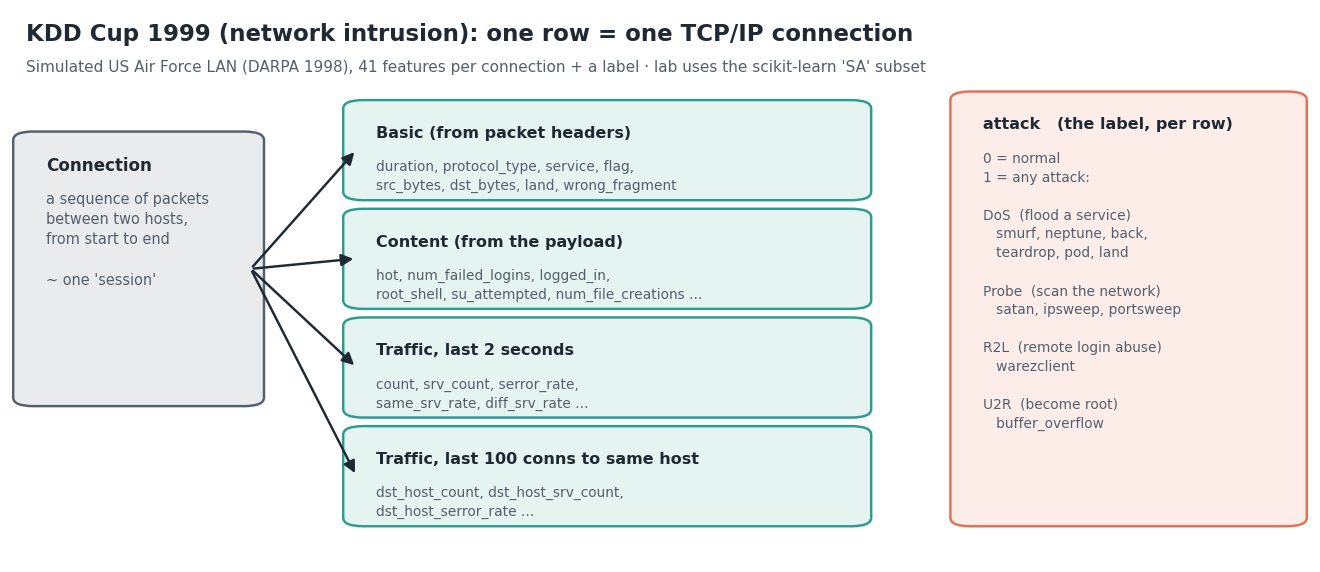

| Feature group | Examples | What it captures |
|---|---|---|
| Basic | `duration`, `protocol_type` (tcp/udp/icmp), `service` (http, ftp, …), `flag` (connection status), `src_bytes`, `dst_bytes` | What the connection was, read from packet headers |
| Content | `hot`, `num_failed_logins`, `logged_in`, `root_shell`, `num_file_creations` | Suspicious actions inside the session (payload) |
| Traffic, last 2 s | `count`, `srv_count`, `serror_rate`, `same_srv_rate` | How many similar connections just happened: floods and scans show up here |
| Traffic, last 100 conns to the same host | `dst_host_count`, `dst_host_srv_count`, `dst_host_serror_rate` | Slower scans that the 2-second window misses |
| Label | `attack` (built from `labels`) | 0 = `normal`, 1 = any attack type |

**The 'SA' subset used here** (`subset="SA", percent10=True`): all 97,278 normal connections from
the 10 % sample plus a small share of attacks, **3,377 in total**. Those attacks are almost all
two **DoS floods**: `smurf` (2,409) and `neptune` (898); the remaining ~70 are spread over `back`,
`satan`, `ipsweep`, `teardrop`, `portsweep`, `warezclient` and others.

**Preprocessing in `load_intrusion()`:** the three text columns (`protocol_type`, `service`,
`flag`) are **one-hot encoded**, which turns 41 features into 96 numeric columns (+ `attack`).

**What you should see when you run the loader**

- `Loaded REAL KDD intrusion: (100655, 97)`.
- After `subsample(...)`: `0: 20000`, `1: 3377`, so a contamination of about **14 %**:
  six times more anomalies than in Part A.
- If it says `SYNTHETIC`, the download failed and a 12-feature simulated stand-in is used.

**Known caveats:** KDD 99 is old (1998 traffic) and contains many **duplicate rows**, especially for
the flood attacks (Tavallaee et al., 2009, *A detailed analysis of the KDD CUP 99 data set*). Use it
to learn the method, not to judge a modern intrusion-detection system.


In [ ]:
def benchmark(X_train, X_test, y_test, contam, svm_sub=4000):
    from sklearn.ensemble import IsolationForest
    from sklearn.neighbors import LocalOutlierFactor
    from sklearn.svm import OneClassSVM
    models = {
        "IsolationForest": IsolationForest(n_estimators=200, contamination=contam,
                                           random_state=RNG, n_jobs=-1).fit(X_train),
        # brute: KDD has thousands of duplicate rows, which make LOF's tree search crawl
        "LOF": LocalOutlierFactor(n_neighbors=20, novelty=True, algorithm="brute",
                                  contamination=contam).fit(X_train),
    }
    sub = np.random.RandomState(RNG).permutation(len(X_train))[:svm_sub]
    models["OneClassSVM"] = OneClassSVM(kernel="rbf", gamma="scale",
                                        nu=max(contam, 0.01)).fit(X_train[sub])
    rows = [evaluate(n, y_test, anomaly_scores(m, X_test), contam) for n, m in models.items()]
    return (pd.DataFrame(rows)[["model","ROC_AUC","PR_AUC","precision","recall","F1"]]
            .round(4).sort_values("PR_AUC", ascending=False).reset_index(drop=True))
print("benchmark() ready.")

In [ ]:
intr = load_intrusion()
label = "attack"
intr_s = subsample(intr, label, n_normal=20000)
print(intr_s[label].value_counts())

### B1 · Prepare & benchmark  ✏️
Reuse everything: split, scale, then call `benchmark()`.

In [ ]:
feat_i = [c for c in intr_s.columns if c != label]
Xi = intr_s[feat_i].astype(float).values; yi = intr_s[label].values
# TODO: stratified split, fit RobustScaler on train only, transform both,
#       compute contamination ci, then call benchmark(Xi_tr, Xi_te, yi_te, ci)
pass